In [548]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/may-2026kaggle-assignment-3/sample_submission.csv
/kaggle/input/competitions/may-2026kaggle-assignment-3/train.csv
/kaggle/input/competitions/may-2026kaggle-assignment-3/test.csv


In [549]:
train_df = pd.read_csv("/kaggle/input/competitions/may-2026kaggle-assignment-3/train.csv")
test_df = pd.read_csv("/kaggle/input/competitions/may-2026kaggle-assignment-3/test.csv")
print(f"Shape of Train data: {train_df.shape}")
train_df.head()

Shape of Train data: (7000, 26)


,ID,mushroom_id,cap-shape,cap-surface,cap-color,bruises,number_of_bruises,odor,gill-attachment,gill-spacing,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
0,1,0,convex,smooth,brown,bruises,7,pungent,gills free from stalk,close,...,white,white,partial,white,1.0,pendant,black,scattered,urban,p
1,2,1,convex,smooth,yellow,bruises,20,almond,gills free from stalk,close,...,white,white,partial,white,1.0,pendant,brown,numerous,grasses,e
2,3,3,convex,scaly,white,bruises,11,pungent,gills free from stalk,close,...,white,white,partial,white,1.0,pendant,black,scattered,urban,p
3,4,4,convex,smooth,gray,no,0,NaN,gills free from stalk,crowded,...,white,white,partial,white,1.0,evanescent,brown,abundant,grasses,e
4,5,5,convex,scaly,yellow,bruises,8,almond,gills free from stalk,close,...,white,white,partial,white,1.0,pendant,black,numerous,grasses,e


### 1. Identify data types of different columns

In [550]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        7000 non-null   int64  
 1   mushroom_id               7000 non-null   int64  
 2   cap-shape                 7000 non-null   object 
 3   cap-surface               7000 non-null   object 
 4   cap-color                 7000 non-null   object 
 5   bruises                   7000 non-null   object 
 6   number_of_bruises         7000 non-null   int64  
 7   odor                      3764 non-null   object 
 8   gill-attachment           7000 non-null   object 
 9   gill-spacing              7000 non-null   object 
 10  gill-size                 7000 non-null   object 
 11  gill-color                7000 non-null   object 
 12  stalk-shape               7000 non-null   object 
 13  stalk-root                6808 non-null   object 
 14  stalk-su

### 2. Present descriptive statistics of numerical columns

In [551]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,7000.0,3500.500000,2020.870275,1.0,1750.75,3500.5,5250.25,7000.0
mushroom_id,7000.0,3850.617714,2208.389867,0.0,2000.75,3755.5,5602.25,8118.0
number_of_bruises,7000.0,5.459571,7.723528,0.0,0.00,0.0,11.00,24.0
ring-number,6964.0,1.080988,0.272836,1.0,1.00,1.0,1.00,2.0


#### Inferr: The dataset contains 7,000 rows where ID and mushroom_id act as uniform identifier fields that must be dropped prior to modeling. number_of_bruises is heavily right-skewed with over 50% of values at zero reaching a maximum of 24, while ring-number is a discrete feature (1 to 2) containing 36 missing values (count is 6,964) that require imputation.

### 3. Identify and handle the missing values

In [552]:
train_df.isnull().sum()

ID                             0
mushroom_id                    0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
number_of_bruises              0
odor                        3236
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                   192
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-type                      0
veil-color                     0
ring-number                   36
ring-type                     36
spore-print-color              0
population                     0
habitat                        0
class                          0
dtype: int64

#### The dataset was checked for missing values before preprocessing. Four columns contained missing values: odor (3,236 missing values), stalk-root (192 missing values), ring-number (36 missing values), and ring-type (36 missing values), while all other columns were complete.

In [553]:
from sklearn.impute import SimpleImputer 

mode_imputer = SimpleImputer(strategy = "most_frequent")

cols = ["stalk-root", "ring-number", "ring-type", "odor"]
train_df[cols] = mode_imputer.fit_transform(train_df[cols])
test_df[cols] = mode_imputer.transform(test_df[cols])
test_id = test_df["ID"] # for later usage

In [554]:
# Removing unwanter columns
train_df = train_df.drop(["ID", "mushroom_id"], axis=1)
test_df = test_df.drop(["ID", "mushroom_id"], axis=1)

In [555]:
# final check 
train_df.isna().sum().sum()   ## only null values in odor

np.int64(0)

### 4. Identify and handle duplicates

In [556]:
train_df.duplicated().sum()

np.int64(0)

In [557]:
test_df.duplicated().sum()

np.int64(0)

#### There isn't any duplicated values in traindf and testdf

### 5. Identify and handle outliers

In [558]:
# Numerical columns 
num_cols = train_df.select_dtypes(include=["int64", "float64"]).columns
for col in num_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train_df[(train_df[col] < lower) | (train_df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers")

number_of_bruises: 0 outliers


#### There are no outliers

### 6. Visualizations 

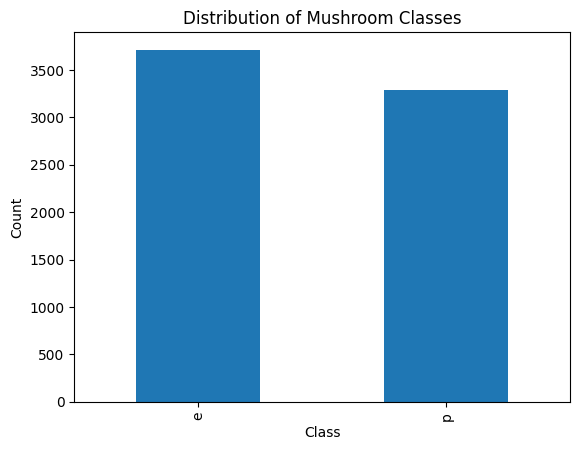

In [559]:
import matplotlib.pyplot as plt

train_df["class"].value_counts().plot(kind="bar")
plt.title("Distribution of Mushroom Classes")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

#### The bar chart shows the distribution of edible and poisonous mushrooms in the dataset.,, its fairly Balanced set

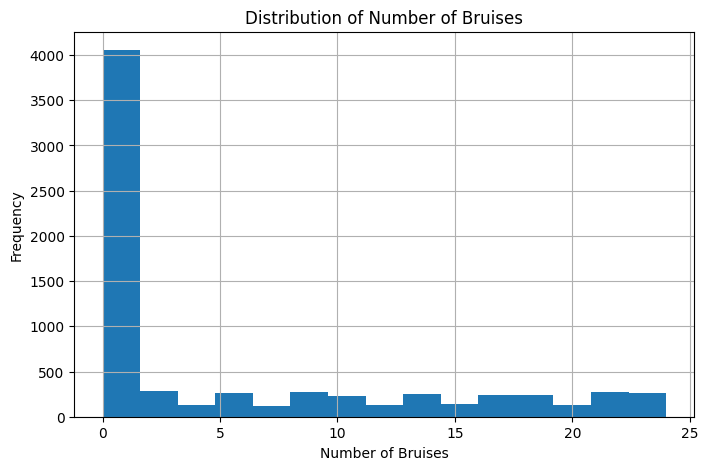

In [560]:
plt.figure(figsize=(8,5))
train_df["number_of_bruises"].hist(bins=15)
plt.title("Distribution of Number of Bruises")
plt.xlabel("Number of Bruises")
plt.ylabel("Frequency")
plt.show()

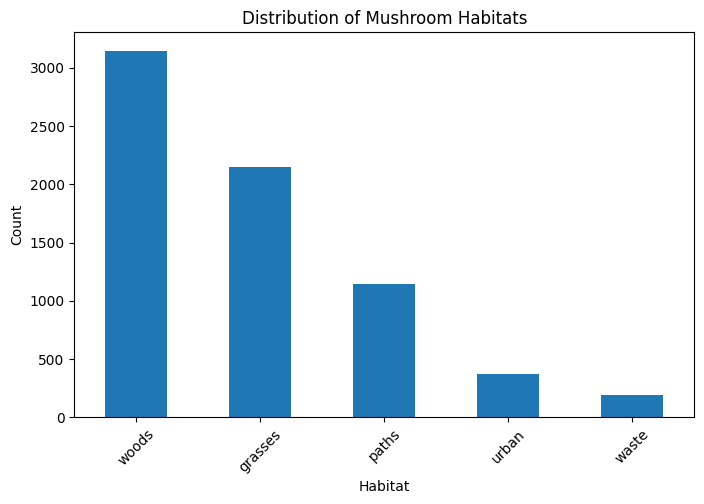

In [561]:
plt.figure(figsize=(8,5))
train_df["habitat"].value_counts().plot(kind="bar")
plt.title("Distribution of Mushroom Habitats")
plt.xlabel("Habitat")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

#### The bar chart shows that mushrooms are not evenly distributed across habitats. Most mushrooms are found in woods, followed by grasses and paths, while urban and waste habitats contain relatively few samples. This indicates that the dataset has an imbalanced distribution of habitat categories, which may lead the model to learn patterns better for the more frequent habitats than for the underrepresented ones.



### 7. Scale Numerical features and Encode Categorical features

In [562]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

y = train_df["class"]
train_df=train_df.drop(["class"], axis=1)

numeric_features = train_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = train_df.select_dtypes(include=["object"]).columns.tolist()

print(f"Numerical:  {numeric_features}")
print("\n\n")
print(f"Categoricaal: {categorical_features}")

Numerical:  ['number_of_bruises']



Categoricaal: ['cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


In [563]:
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# combine both pipeline 
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features),
])

train_df = preprocessor.fit_transform(train_df)
test_df = preprocessor.transform(test_df)

In [564]:
# splitting the train_df in 80: 20

# encoding target class 'e' = edible (0), 'p' = poisonous (1)
y = y.map({'e': 0, 'p': 1})
X_train, X_test, y_train, y_test = train_test_split(
    train_df,
    y,
    test_size = 0.2,
    random_state=42,
    stratify=y
)
X_train = X_train.toarray()
X_test = X_test.toarray()

#### The numerical feature was standardized using StandardScaler to bring it to a common scale, which benefits machine learning algorithms that are sensitive to feature magnitudes. The categorical features were encoded using OneHotEncoder to convert them into numerical representations without introducing any ordinal relationship between categories. Both preprocessing steps were implemented using Pipeline and ColumnTransformer

### 8. Model Building 

In [565]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score
from sklearn.ensemble import HistGradientBoostingClassifier

import catboost as cb
import lightgbm as lgb
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

In [566]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "Hist" :HistGradientBoostingClassifier(max_depth=6, random_state=42),
    "KNN": KNeighborsClassifier(),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42),
    "GradientBoosting": GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300,
    verbose=-1, 
    min_child_samples=1, 
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42),
    "SVM (RBF Kernel)": SVC(kernel="rbf", C=1.0, probability=True, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "CatBoost": cb.CatBoostClassifier(iterations=200, learning_rate=0.05, verbose=0, random_seed=42),
    "MLP Neural Net": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42),
    "Bernoulli Naive Bayes": BernoulliNB()
}
results = {}

In [567]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)


    acc = accuracy_score(y_test, y_pred)

    results[name] = acc
    print(f"{name}: ACC = {acc:.4f}")

LogisticRegression: ACC = 1.0000
Hist: ACC = 1.0000
KNN: ACC = 1.0000
DecisionTree: ACC = 1.0000
RandomForest: ACC = 1.0000
GradientBoosting: ACC = 1.0000
AdaBoost: ACC = 0.9943
XGBoost: ACC = 1.0000
LightGBM: ACC = 1.0000
SVM (RBF Kernel): ACC = 1.0000
Extra Trees: ACC = 1.0000
CatBoost: ACC = 1.0000
MLP Neural Net: ACC = 1.0000
Bernoulli Naive Bayes: ACC = 0.9064


#### 3 models for hyper param tuning

1. LightGBM (Tree Gradient Boosting) <br>
2. Random Forest<br>
3. XGBoost 

In [568]:
performance_df = pd.DataFrame.from_dict(results, orient='index', columns=['acc'])
performance_df = performance_df.sort_values(by='acc', ascending=False)

performance_df

,acc
LogisticRegression,1.000000
Hist,1.000000
KNN,1.000000
DecisionTree,1.000000
RandomForest,1.000000
GradientBoosting,1.000000
XGBoost,1.000000
LightGBM,1.000000
SVM (RBF Kernel),1.000000
Extra Trees,1.000000


### 9. Hyperparameter Tuning and Prep

In [569]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb
import xgboost as xgb

# Format inputs consistently as dense arrays
X_tr = X_train.toarray() if hasattr(X_train, "toarray") else np.asarray(X_train)
X_te = test_df.toarray() if hasattr(test_df, "toarray") else np.asarray(test_df)
y_tr = np.asarray(y_train)

# Define 3 distinct models and their hyperparameter grids
tuning_configs = {
    "LightGBM": (
        lgb.LGBMClassifier(random_state=42, verbose=-1),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [3, 5, 8],
            "learning_rate": [0.01, 0.05, 0.1],
            "num_leaves": [15, 31, 63],
        },
    ),
    "XGBoost": (
        xgb.XGBClassifier(random_state=42, eval_metric="logloss"),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [3, 5, 8],
            "learning_rate": [0.01, 0.05, 0.1],
            "subsample": [0.8, 1.0],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "n_estimators": [100, 200, 300],
            "max_depth": [5, 10, 15, None],
            "min_samples_split": [2, 5],
        },
    ),
}

In [570]:
# Perform Hyperparameter Tuning for all 3 models
best_tuned_models = {}

print("--- Running Hyperparameter Tuning ---")
for name, (base_model, params) in tuning_configs.items():
    search = RandomizedSearchCV(
        base_model,
        param_distributions=params,
        n_iter=5,
        cv=3,
        scoring="accuracy",
        random_state=42,
        n_jobs=-1,
    )
    search.fit(X_tr, y_tr)
    best_tuned_models[name] = search.best_estimator_
    print(f"{name:<12} | Best CV Accuracy: {search.best_score_:.4f}")
    print(f"Best Params : {search.best_params_}\n")

--- Running Hyperparameter Tuning ---


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/ut

LightGBM     | Best CV Accuracy: 1.0000
Best Params : {'num_leaves': 15, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.05}

XGBoost      | Best CV Accuracy: 1.0000
Best Params : {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05}

RandomForest | Best CV Accuracy: 1.0000
Best Params : {'n_estimators': 300, 'min_samples_split': 2, 'max_depth': 10}



In [571]:
# Generate Final submission.csv using the best tuned LightGBM model
best_lgb = best_tuned_models["LightGBM"]
final_preds = best_lgb.predict(X_te)

submission = pd.DataFrame({"ID": test_id, "class": final_preds})

# Map numeric predictions back to original target labels
submission["class"] = submission["class"].map({0: "e", 1: "p"})
submission.to_csv("submission.csv", index=False)

print("Final Submission Created")
print("\nPredicted Class Distribution:")
print(submission["class"].value_counts(normalize=True))
print(submission.head())

Final Submission Created

Predicted Class Distribution:
class
p    0.544484
e    0.455516
Name: proportion, dtype: float64
   ID class
0   1     e
1   2     e
2   3     e
3   4     e
4   5     e
